# Simulação

Projete passa-baixas de 100 Hz a fs = 1000 Hz, compare ordens 30 e 60 e janelas retangular, Hann e Hamming.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


boxcar ordem 30 soma dos coeficientes 1.0000000000000002 simetria: True
hann ordem 30 soma dos coeficientes 1.0000000000000002 simetria: True
hamming ordem 30 soma dos coeficientes 1.0 simetria: True
blackman ordem 30 soma dos coeficientes 0.9999999999999998 simetria: True
boxcar ordem 60 soma dos coeficientes 0.9999999999999999 simetria: True
hann ordem 60 soma dos coeficientes 1.0 simetria: True
hamming ordem 60 soma dos coeficientes 0.9999999999999999 simetria: True
blackman ordem 60 soma dos coeficientes 1.0 simetria: True


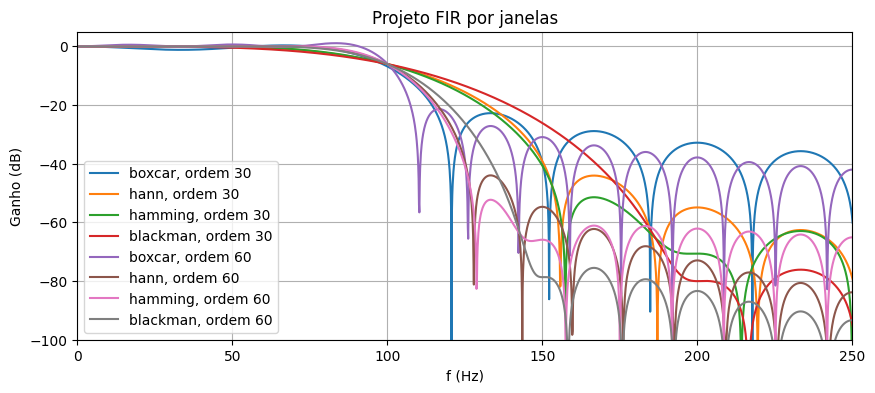

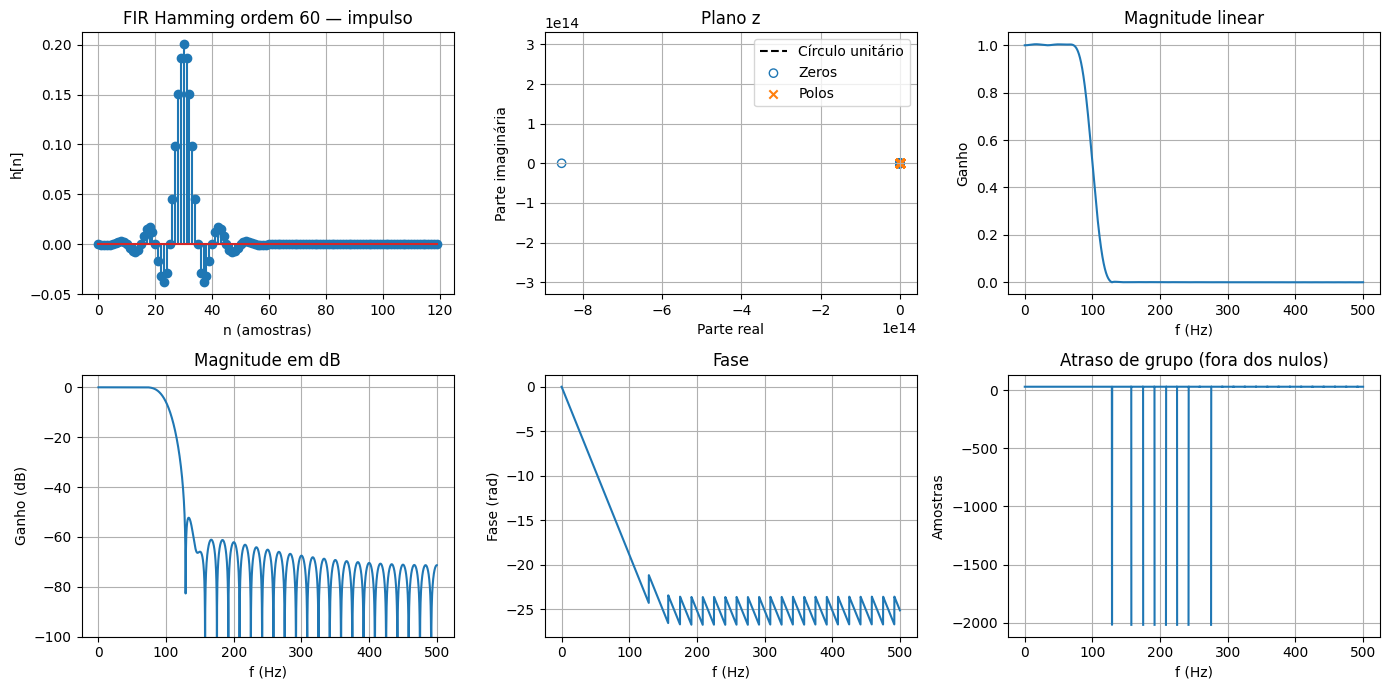

b = [-6.25062962e-19 -5.33546726e-04 -9.75742199e-04 -1.15191036e-03
 -8.63739968e-04  1.10658267e-18  1.31137641e-03  2.61380332e-03
  3.20212767e-03  2.40736791e-03 -2.42211898e-18 -3.48266003e-03
 -6.70576757e-03 -7.93023216e-03 -5.76478856e-03  4.21917499e-18
  7.87630045e-03  1.48342877e-02  1.72463226e-02  1.23940257e-02
 -6.01623101e-18 -1.68833441e-02 -3.21516098e-02 -3.82203158e-02
 -2.85052982e-02  7.33176731e-18  4.50118960e-02  9.88527024e-02
  1.50169453e-01  1.87031968e-01  2.00434649e-01  1.87031968e-01
  1.50169453e-01  9.88527024e-02  4.50118960e-02  7.33176731e-18
 -2.85052982e-02 -3.82203158e-02 -3.21516098e-02 -1.68833441e-02
 -6.01623101e-18  1.23940257e-02  1.72463226e-02  1.48342877e-02
  7.87630045e-03  4.21917499e-18 -5.76478856e-03 -7.93023216e-03
 -6.70576757e-03 -3.48266003e-03 -2.42211898e-18  2.40736791e-03
  3.20212767e-03  2.61380332e-03  1.31137641e-03  1.10658267e-18
 -8.63739968e-04 -1.15191036e-03 -9.75742199e-04 -5.33546726e-04
 -6.25062962e-19]
a =

In [2]:
for L in [31,61]:
    for janela in ['boxcar','hann','hamming','blackman']:
        b=signal.firwin(L,100,window=janela,fs=1000)
        f,H=signal.freqz(b,fs=1000,worN=4096)
        plt.plot(f,20*np.log10(np.maximum(abs(H),1e-8)),label=f'{janela}, ordem {L-1}')
        print(janela,'ordem',L-1,'soma dos coeficientes',b.sum(),'simetria:',np.allclose(b,b[::-1]))
plt.xlim(0,250); plt.ylim(-100,5); plt.xlabel('f (Hz)'); plt.ylabel('Ganho (dB)'); plt.title('Projeto FIR por janelas'); plt.legend(); plt.show()
analisar(signal.firwin(61,100,fs=1000),fs=1000,nome='FIR Hamming ordem 60')